# Notebook d'orchestration - Résultats Semaine 3

Ce notebook présente les résultats des entraînements 1D et 2D du Normalizing Flow (RealNVP) sur la distribution cible $w_J(\theta)$.

In [1]:
import torch
import matplotlib.pyplot as plt
import json
from IPython.display import display, Image
from flow import RealNVPFlow
from diagnostics import compute_ess, compare_to_theoretical_1d, compare_2d
from oracle import log_w_J_1d, log_w_J_2d, solve_lambda_star, theoretical_jeffreys_pdf_1d

ModuleNotFoundError: No module named 'flow'

## 1. Résultats 1D

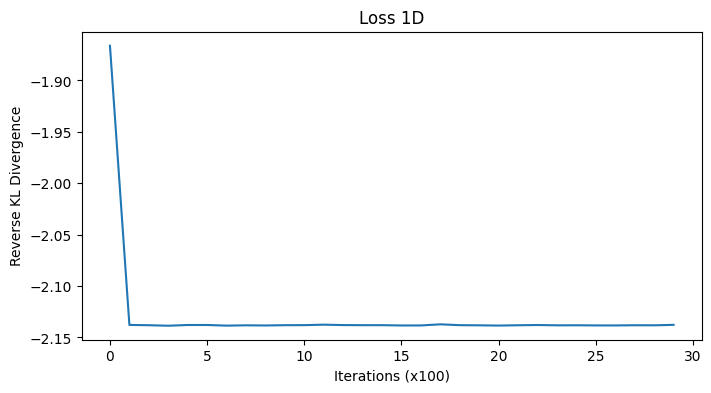

In [2]:
try:
    with open('../checkpoints/history_1d.json') as f:
        history_1d = json.load(f)
    plt.figure(figsize=(8, 4))
    plt.plot(history_1d['loss'])
    plt.title('Loss 1D')
    plt.xlabel('Iterations (x100)')
    plt.ylabel('Reverse KL Divergence')
    plt.show()
except FileNotFoundError:
    print("History file not found.")

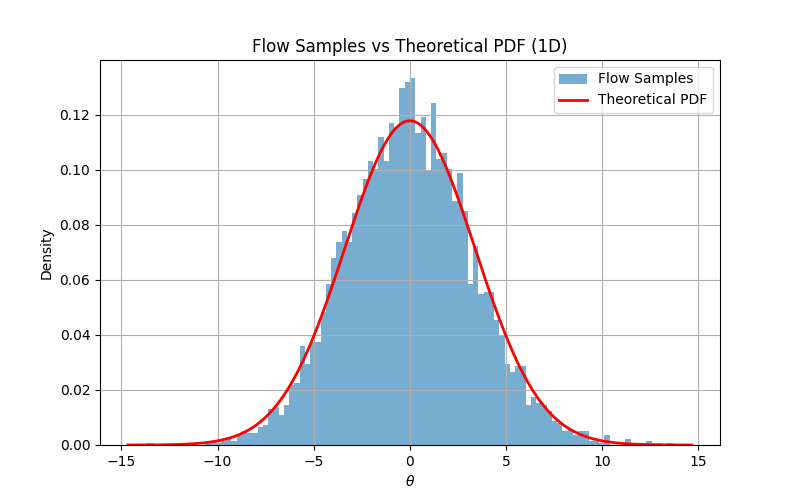

In [3]:
try:
    display(Image(filename='../flow_vs_theoretical_1d.png'))
except Exception:
    print("Image not found.")

## 2. Résultats 2D

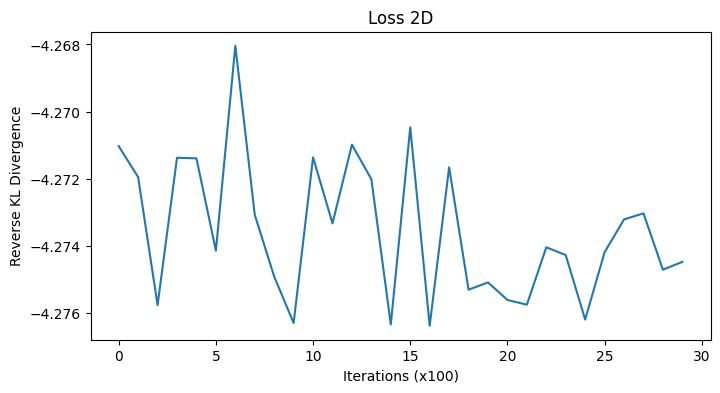

In [4]:
try:
    with open('../checkpoints/history_2d.json') as f:
        history_2d = json.load(f)
    plt.figure(figsize=(8, 4))
    plt.plot(history_2d['loss'])
    plt.title('Loss 2D')
    plt.xlabel('Iterations (x100)')
    plt.ylabel('Reverse KL Divergence')
    plt.show()
except FileNotFoundError:
    print("History file not found.")

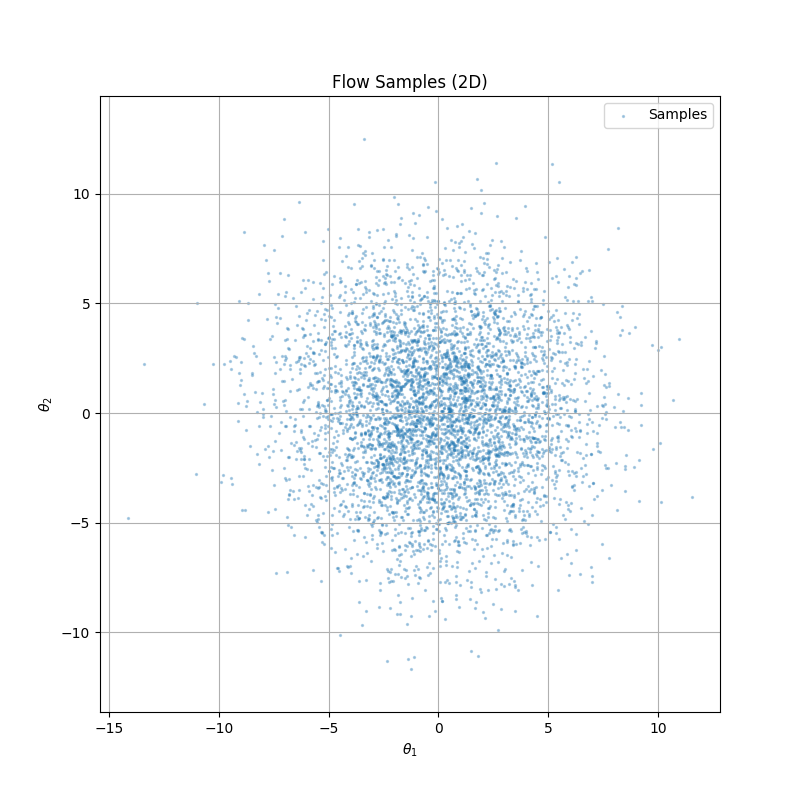

In [5]:
try:
    display(Image(filename='../flow_samples_2d.png'))
except Exception:
    print("Image not found.")

## Tableau Récapitulatif des Hyperparamètres
| Paramètre | 1D | 2D | Impact observé |
|---|---|---|---|
| **Coupling Layers** | 6 | 6 | 6 est le minimum pour une certaine flexibilité, mais en 1D cela reste limité. |
| **Hidden Dim** | 64 | 64 | Assez large pour les réseaux s et t. |
| **Learning Rate** | 1e-3 | 1e-3 | Permet une convergence stable avec Adam. |
| **Batch Size** | 1024 | 1024 | Grand batch nécessaire pour une variance de gradient faible sur le Reverse KL. |
| **Gradient Clipping** | Oui (1.0) | Oui (1.0) | Empêche les instabilités dans les log-déterminants. |